# Dados hidrometeorológicos da ANA

Leitura dos arquivos XML da estação 87444000 (Usina do Gasômetro, Porto Alegre).

In [1]:
from pathlib import Path
import xml.etree.ElementTree as ET

import pandas as pd

PROJECT_DIR = Path.cwd() if (Path.cwd() / "dados").exists() else Path.cwd().parent
DATA_DIR = PROJECT_DIR / "dados" / "originais" / "ana"

def read_ana_xml(path: Path) -> pd.DataFrame:
    root = ET.parse(path).getroot()
    rows = []
    for record in root.findall(".//DadosHidrometereologicos"):
        rows.append({
            child.tag: child.text
            for child in record
        })

    return pd.DataFrame(rows)


xml_files = sorted(DATA_DIR.glob("ana_*.xml"))
df_ana = pd.concat(
    [read_ana_xml(path) for path in xml_files],
    ignore_index=True,
)
df_ana["DataHora"] = pd.to_datetime(df_ana["DataHora"].str.strip())
for column in ["CodEstacao", "Vazao", "Nivel", "Chuva"]:
    df_ana[column] = pd.to_numeric(df_ana[column], errors="coerce")

df_ana = df_ana.sort_values("DataHora").reset_index(drop=True)
df_ana

,CodEstacao,DataHora,Vazao,Nivel,Chuva
0,87444000,2024-05-03 00:00:00,NaN,NaN,0.0
1,87444000,2024-05-03 00:15:00,NaN,NaN,0.0
2,87444000,2024-05-03 00:30:00,NaN,NaN,0.0
3,87444000,2024-05-03 00:45:00,NaN,NaN,0.0
4,87444000,2024-05-03 01:00:00,NaN,NaN,0.0
...,...,...,...,...,...
5546,87444000,2024-06-30 22:45:00,NaN,329.0,0.0
5547,87444000,2024-06-30 23:00:00,NaN,329.0,0.0
5548,87444000,2024-06-30 23:15:00,NaN,329.0,0.0
5549,87444000,2024-06-30 23:30:00,NaN,329.0,0.0


In [2]:
df_ana.info()
df_ana.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 5551 entries, 0 to 5550
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   CodEstacao  5551 non-null   int64         
 1   DataHora    5551 non-null   datetime64[us]
 2   Vazao       0 non-null      float64       
 3   Nivel       5444 non-null   float64       
 4   Chuva       4637 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(1)
memory usage: 217.0 KB


,CodEstacao,DataHora,Vazao,Nivel,Chuva
count,5551.0,5551,0.0,5444.000000,4637.000000
mean,87444000.0,2024-06-01 18:29:10.549450,NaN,377.883909,0.091093
min,87444000.0,2024-05-03 00:00:00,NaN,248.000000,0.000000
25%,87444000.0,2024-05-17 23:37:30,NaN,319.000000,0.000000
50%,87444000.0,2024-06-02 02:00:00,NaN,355.000000,0.000000
75%,87444000.0,2024-06-16 12:52:30,NaN,453.000000,0.000000
max,87444000.0,2024-06-30 23:45:00,NaN,535.000000,12.000000
std,0.0,NaN,NaN,81.536853,0.480240


## Busca por inconsistências

Esta etapa identifica problemas que precisam ser avaliados antes da limpeza: duplicidades, intervalos de tempo irregulares, valores ausentes, valores negativos e possíveis mudanças abruptas no nível. Os dados originais não são alterados.

In [3]:
df_auditoria = df_ana.copy()
df_auditoria["Intervalo_min"] = (
    df_auditoria["DataHora"].diff().dt.total_seconds().div(60)
)
df_auditoria["Data_duplicada"] = df_auditoria["DataHora"].duplicated(keep=False)
df_auditoria["Nivel_negativo"] = df_auditoria["Nivel"] < 0
df_auditoria["Chuva_negativa"] = df_auditoria["Chuva"] < 0
df_auditoria["Nivel_salto_abrupto"] = (
    df_auditoria["Nivel"].diff().abs() > 20
)

resumo_auditoria = pd.DataFrame(
    {
        "Problema": [
            "Linhas duplicadas",
            "Datas duplicadas",
            "Intervalos diferentes de 15 minutos",
            "Nível ausente",
            "Chuva ausente",
            "Vazão ausente",
            "Nível negativo",
            "Chuva negativa",
            "Saltos de nível acima de 20 unidades",
        ],
        "Quantidade": [
            df_auditoria.duplicated().sum(),
            df_auditoria["Data_duplicada"].sum(),
            df_auditoria["Intervalo_min"].iloc[1:].ne(15).sum(),
            df_auditoria["Nivel"].isna().sum(),
            df_auditoria["Chuva"].isna().sum(),
            df_auditoria["Vazao"].isna().sum(),
            df_auditoria["Nivel_negativo"].sum(),
            df_auditoria["Chuva_negativa"].sum(),
            df_auditoria["Nivel_salto_abrupto"].sum(),
        ],
    }
)

resumo_auditoria

,Problema,Quantidade
0,Linhas duplicadas,0
1,Datas duplicadas,0
2,Intervalos diferentes de 15 minutos,23
3,Nível ausente,107
4,Chuva ausente,914
5,Vazão ausente,5551
6,Nível negativo,0
7,Chuva negativa,0
8,Saltos de nível acima de 20 unidades,0


### Registros e intervalos para investigação

As tabelas seguintes mostram exatamente onde estão os intervalos irregulares e quais registros foram marcados por alguma regra de qualidade. Um intervalo diferente de 15 minutos indica possível ausência de observações ou mudança na frequência de coleta.

In [4]:
intervalos = pd.DataFrame(
    {
        "Inicio": df_ana["DataHora"].iloc[:-1].to_numpy(),
        "Fim": df_ana["DataHora"].iloc[1:].to_numpy(),
    }
)
intervalos["Intervalo_min"] = (
    intervalos["Fim"] - intervalos["Inicio"]
).dt.total_seconds().div(60)
intervalos_irregulares = intervalos.query("Intervalo_min != 15")

nulos = (
    df_ana.isna()
    .sum()
    .rename("Quantidade")
    .to_frame()
    .assign(Percentual=lambda tabela: tabela["Quantidade"] / len(df_ana) * 100)
    .sort_values("Quantidade", ascending=False)
)

colunas_marcacao = [
    "DataHora",
    "CodEstacao",
    "Nivel",
    "Chuva",
    "Intervalo_min",
    "Data_duplicada",
    "Nivel_negativo",
    "Chuva_negativa",
    "Nivel_salto_abrupto",
]
registros_marcados = df_auditoria.loc[
    df_auditoria[
        [
            "Data_duplicada",
            "Nivel_negativo",
            "Chuva_negativa",
            "Nivel_salto_abrupto",
        ]
    ].any(axis=1),
    colunas_marcacao,
]

print("Intervalos irregulares:")
intervalos_irregulares


Intervalos irregulares:


,Inicio,Fim,Intervalo_min
93,2024-05-03 23:15:00,2024-05-04 00:00:00,45.0
94,2024-05-04 00:00:00,2024-05-04 01:00:00,60.0
95,2024-05-04 01:00:00,2024-05-04 02:00:00,60.0
96,2024-05-04 02:00:00,2024-05-04 03:00:00,60.0
97,2024-05-04 03:00:00,2024-05-04 04:00:00,60.0
98,2024-05-04 04:00:00,2024-05-04 05:00:00,60.0
99,2024-05-04 05:00:00,2024-05-04 06:00:00,60.0
100,2024-05-04 06:00:00,2024-05-04 08:00:00,120.0
101,2024-05-04 08:00:00,2024-05-04 09:00:00,60.0
102,2024-05-04 09:00:00,2024-05-04 10:00:00,60.0


Notam-se diversas lacunas e coletam em tempos distintos do padrão de 15 minutos.

### Ausências e marcações de qualidade

A tabela de nulos mostra a proporção de dados ausentes por coluna.

In [5]:
print("Valores ausentes:")
display(nulos)

Valores ausentes:


,Quantidade,Percentual
Vazao,5551,100.000000
Chuva,914,16.465502
Nivel,107,1.927581
CodEstacao,0,0.000000
DataHora,0,0.000000


## Visualizações

As visualizações abaixo mostram a evolução do nível da estação, a chuva registrada, as distribuições das variáveis e a completude dos dados.

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Agregacao diaria para facilitar a leitura
df_diario = (
    df_ana.set_index("DataHora")
    .resample("D")
    .agg(
        Nivel_medio=("Nivel", "mean"),
        Nivel_maximo=("Nivel", "max"),
        Chuva_total=("Chuva", "sum"),
    )
)
df_diario.head()

,Nivel_medio,Nivel_maximo,Chuva_total
DataHora,,,
2024-05-03,469.500000,480.0,1.8
2024-05-04,513.950000,527.0,0.0
2024-05-05,528.479167,535.0,0.0
2024-05-06,527.187500,533.0,0.0
2024-05-07,524.916667,531.0,0.0


### Evolução temporal do nível e da chuva

O primeiro gráfico mostra como o nível da água variou ao longo do período analisado. O segundo mostra o volume de chuva acumulado em cada dia, facilitando a identificação dos dias mais chuvosos.

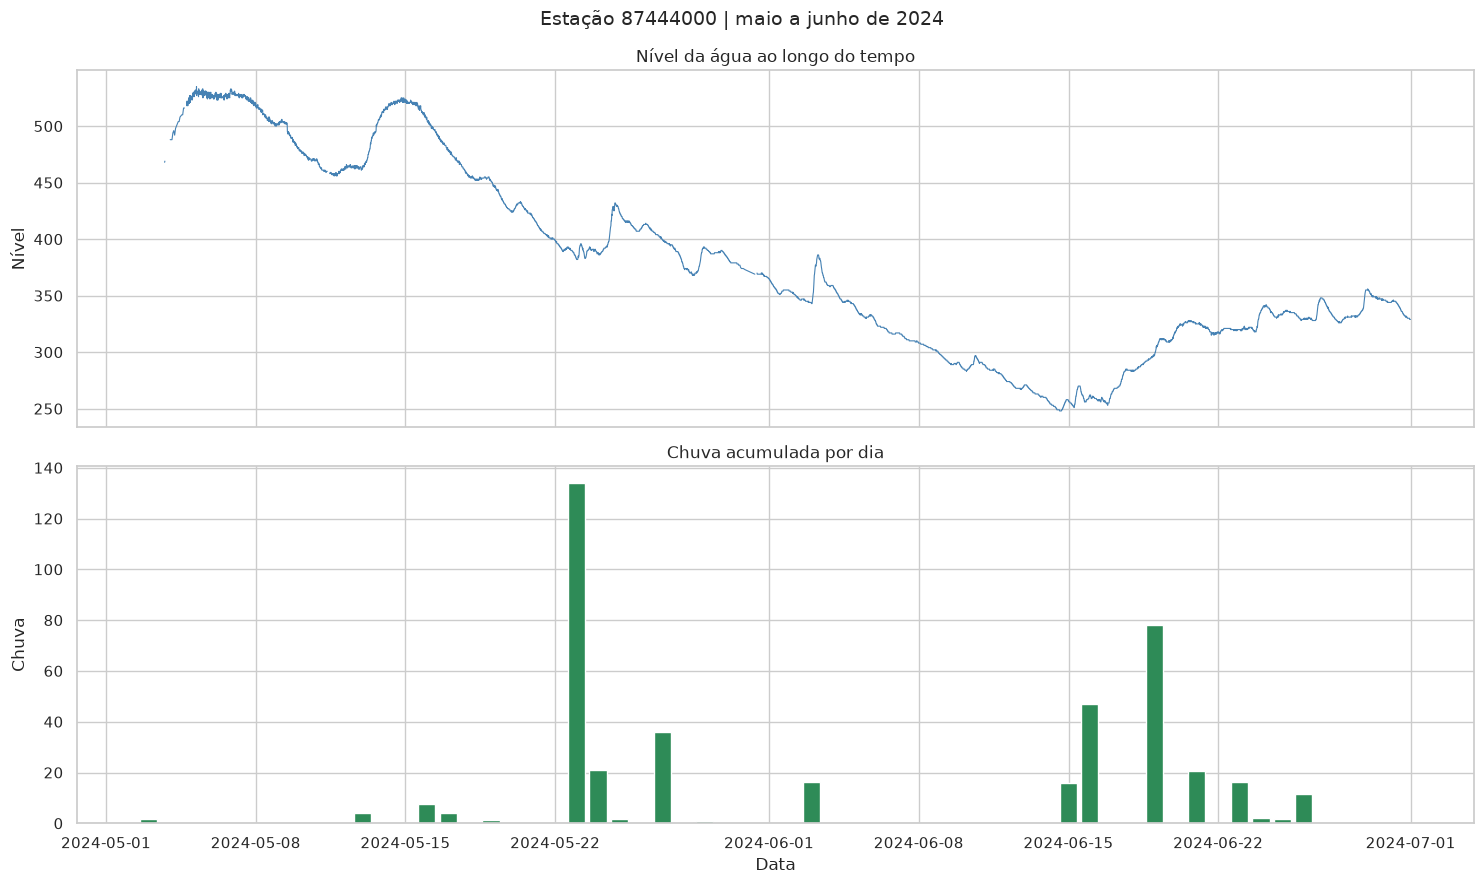

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

axes[0].plot(df_ana["DataHora"], df_ana["Nivel"], color="steelblue", linewidth=0.8)
axes[0].set_title("Nível da água ao longo do tempo")
axes[0].set_ylabel("Nível")

axes[1].bar(
    df_diario.index,
    df_diario["Chuva_total"],
    width=0.8,
    color="seagreen",
)
axes[1].set_title("Chuva acumulada por dia")
axes[1].set_ylabel("Chuva")
axes[1].set_xlabel("Data")

fig.suptitle("Estação 87444000 | maio a junho de 2024", fontsize=14)
fig.tight_layout()
plt.show()

O nível começa elevado, atinge o máximo de 535 no início de maio e depois apresenta uma queda gradual até o final de junho. A chuva registrada está concentrada em poucos períodos; entretanto, a interpretação da relação entre chuva e nível deve ser cautelosa, porque notamos diversas lacunas entre os dados das chuvas. Também é possível notar que os valores dos níveis não aparentam condizer bem com os valores  das chuvas, evidenciando uma possível inconsistência nos dados coletados.

### Distribuição dos níveis registrados

O histograma mostra quais valores de nível aparecem com maior frequência. A curva suavizada ajuda a visualizar a concentração dos dados, enquanto o boxplot resume a mediana, a dispersão e possíveis valores extremos.

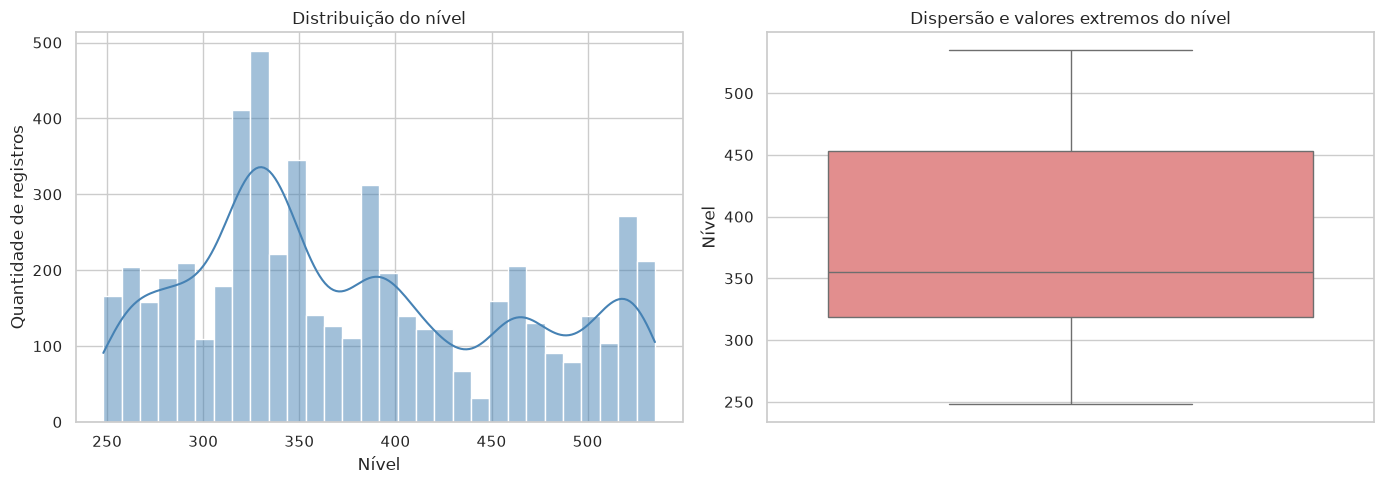

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_ana["Nivel"].dropna(), bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribuição do nível")
axes[0].set_xlabel("Nível")
axes[0].set_ylabel("Quantidade de registros")

sns.boxplot(y=df_ana["Nivel"], ax=axes[1], color="lightcoral")
axes[1].set_title("Dispersão e valores extremos do nível")
axes[1].set_ylabel("Nível")

fig.tight_layout()
plt.show()

Os níveis variam de 248 a 535, com uma distribuição bastante espalhada e não concentrada em um único valor. O boxplot ajuda a investigar valores extremos, mas não substitui a análise temporal: um valor extremo pode representar uma condição hidrológica real, e não necessariamente um erro de medição. Como estamos lidando com o período das cheias, precisamos considerar também estes valores extremos.

### Completude dos dados

Este gráfico compara a porcentagem de registros preenchidos em cada variável. Ele evidencia quais campos podem ser usados diretamente na análise e quais apresentam muitos valores ausentes.

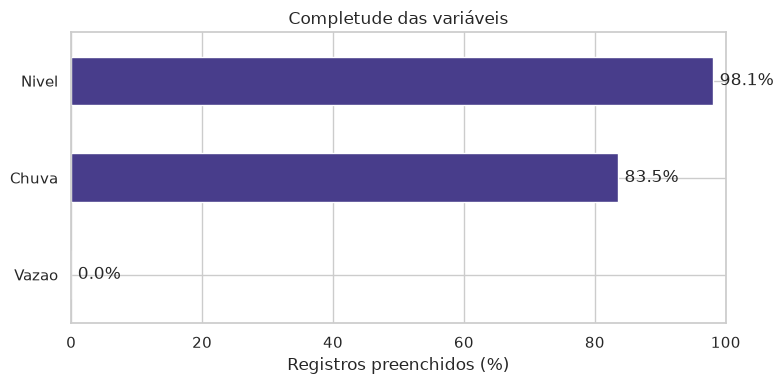

In [9]:
completude = df_ana[["Vazao", "Nivel", "Chuva"]].notna().mean().mul(100)

ax = completude.sort_values().plot.barh(figsize=(8, 4), color="darkslateblue")
ax.set_title("Completude das variáveis")
ax.set_xlabel("Registros preenchidos (%)")
ax.set_xlim(0, 100)

for index, value in enumerate(completude.sort_values()):
    ax.text(value + 1, index, f"{value:.1f}%", va="center")

plt.tight_layout()
plt.show()

Nivel é a variável mais completa, com aproximadamente 98,1% dos registros preenchidos, enquanto Chuva possui cerca de 83,5%. Vazao está ausente em 100% dos registros e, portanto, não pode ser usada nesta análise sem buscar outra fonte ou arquivo. As ausências devem ser preservadas e documentadas durante a limpeza.

## Limpeza dos dados

Tratamentos decididos a partir da análise acima. Cada alteração está comentada no código com **ALTERAÇÃO**.

| Problema encontrado | Tratamento | Por quê |
|---|---|---|
| `Vazao` 100% ausente | **remover a coluna** | não tem nenhuma informação |
| `CodEstacao` igual em todas as linhas | **remover a coluna** (fica no nome do arquivo e nos metadados) | constante, não acrescenta informação |
| `Nivel` em centímetros (máx. 535 = 5,35 m, o recorde de maio/2024) | **criar `nivel_m` em metros** | mesma unidade do INCT (3,0 a 10,0 m) |
| `Nivel` ausente (1,9%) e `Chuva` ausente (16,5%) | **manter como nulo** | não inventar valores; as ausências ficam documentadas |
| Intervalos diferentes de 15 min (leituras horárias em 04/05 e lacuna de 11 h em 30–31/05) | **manter as leituras como vieram** e registrar o intervalo em `intervalo_min` | não criar leituras que não existem; quem usar pode filtrar |
| Valores extremos de nível | **manter** | período de cheia: os extremos são reais |
| Sem duplicatas e sem valores negativos | nada a fazer | conferido na auditoria |
| Nomes de colunas em formatos diferentes | **padronizar em minúsculas** (`data_hora`, `nivel_m`, `chuva_mm`) | consistência com as outras bases |

In [10]:
ana_limpo = df_ana.copy()

# ALTERAÇÃO: remove Vazao (100% ausente) e CodEstacao (valor único: 87444000)
assert ana_limpo["Vazao"].isna().all()
assert ana_limpo["CodEstacao"].nunique() == 1
ana_limpo = ana_limpo.drop(columns=["Vazao", "CodEstacao"])

# ALTERAÇÃO: nível de centímetros para metros (535 cm -> 5,35 m)
ana_limpo["nivel_m"] = ana_limpo["Nivel"] / 100

# ALTERAÇÃO: intervalo (em minutos) desde a leitura anterior, para marcar as lacunas
ana_limpo["intervalo_min"] = ana_limpo["DataHora"].diff().dt.total_seconds().div(60)

# ALTERAÇÃO: nomes padronizados; Chuva já está em mm, só renomeamos
ana_limpo = ana_limpo.rename(columns={"DataHora": "data_hora", "Chuva": "chuva_mm"})
ana_limpo = ana_limpo[["data_hora", "nivel_m", "chuva_mm", "intervalo_min"]]

# Valores ausentes de nivel_m e chuva_mm NÃO são preenchidos (ficam null no JSON)
ana_limpo

,data_hora,nivel_m,chuva_mm,intervalo_min
0,2024-05-03 00:00:00,NaN,0.0,NaN
1,2024-05-03 00:15:00,NaN,0.0,15.0
2,2024-05-03 00:30:00,NaN,0.0,15.0
3,2024-05-03 00:45:00,NaN,0.0,15.0
4,2024-05-03 01:00:00,NaN,0.0,15.0
...,...,...,...,...
5546,2024-06-30 22:45:00,3.29,0.0,15.0
5547,2024-06-30 23:00:00,3.29,0.0,15.0
5548,2024-06-30 23:15:00,3.29,0.0,15.0
5549,2024-06-30 23:30:00,3.29,0.0,15.0


### Verificação

Conferimos que a limpeza não perdeu nem criou leituras e que o nível máximo bate com o recorde de 5,35 m.

In [11]:
assert len(ana_limpo) == len(df_ana)                       # nenhuma linha removida
assert ana_limpo["data_hora"].is_unique                    # sem datas duplicadas
assert ana_limpo["data_hora"].is_monotonic_increasing      # em ordem cronológica
assert ana_limpo["nivel_m"].max() == 5.35                  # recorde de maio/2024
assert (ana_limpo["chuva_mm"].dropna() >= 0).all()

print("Período:", ana_limpo["data_hora"].min(), "a", ana_limpo["data_hora"].max())
print("Leituras:", len(ana_limpo))
print("Nível ausente:", ana_limpo["nivel_m"].isna().sum(), "| Chuva ausente:", ana_limpo["chuva_mm"].isna().sum())
print("Leituras com intervalo diferente de 15 min:", ana_limpo["intervalo_min"].iloc[1:].ne(15).sum())

Período: 2024-05-03 00:00:00 a 2024-06-30 23:45:00
Leituras: 5551
Nível ausente: 107 | Chuva ausente: 914
Leituras com intervalo diferente de 15 min: 23


Para validar as alteracoes feitas, decidimos criar estes graficos para comparar o antes e o depois e confirmar a consistencia dos niveis em relacao ao tempo

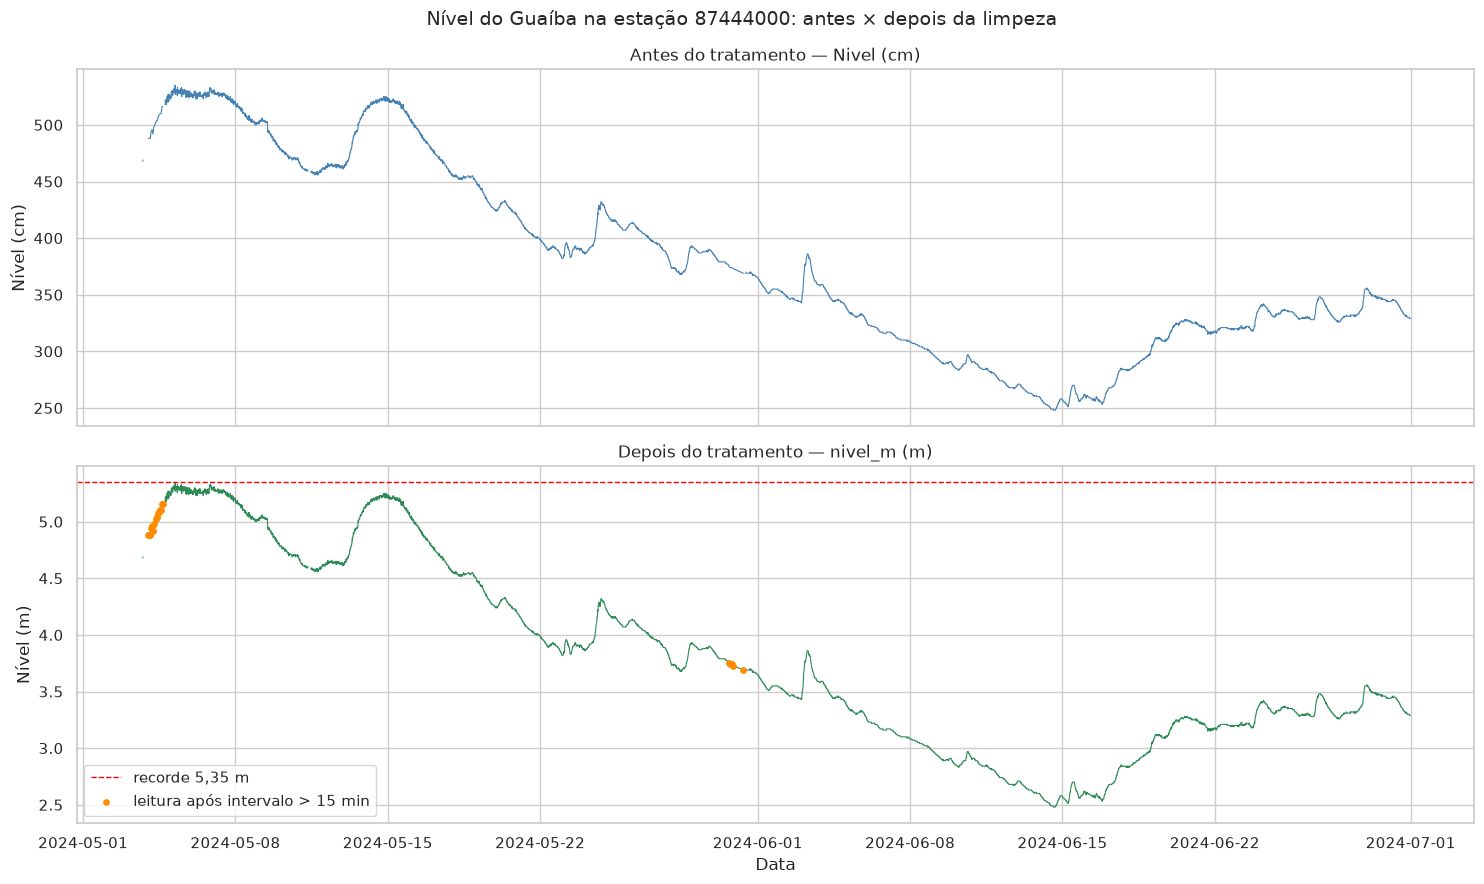

Maior diferença entre antes e depois (em cm): 0.000000


In [12]:
# Comparação visual: mesmo nível antes (cm) e depois (m) do tratamento.
# Se a limpeza estiver correta, as duas curvas têm exatamente o mesmo formato, só muda a escala do eixo.
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

axes[0].plot(df_ana["DataHora"], df_ana["Nivel"], color="steelblue", linewidth=0.8)
axes[0].set_title("Antes do tratamento — Nivel (cm)")
axes[0].set_ylabel("Nível (cm)")

axes[1].plot(ana_limpo["data_hora"], ana_limpo["nivel_m"], color="seagreen", linewidth=0.8)
axes[1].axhline(5.35, color="red", linestyle="--", linewidth=1, label="recorde 5,35 m")
# Marca as leituras com intervalo diferente de 15 minutos (lacunas mantidas)
lacunas = ana_limpo[ana_limpo["intervalo_min"].gt(15)]
axes[1].scatter(lacunas["data_hora"], lacunas["nivel_m"], color="darkorange", s=15, zorder=3,
                label="leitura após intervalo > 15 min")
axes[1].set_title("Depois do tratamento — nivel_m (m)")
axes[1].set_ylabel("Nível (m)")
axes[1].set_xlabel("Data")
axes[1].legend()

fig.suptitle("Nível do Guaíba na estação 87444000: antes × depois da limpeza", fontsize=14)
fig.tight_layout()
plt.show()

# Conferência numérica: depois x 100 deve ser igual ao antes em todas as leituras com valor
diferenca = (ana_limpo["nivel_m"] * 100 - df_ana["Nivel"]).abs().max()
print(f"Maior diferença entre antes e depois (em cm): {diferenca:.6f}")

### Exportação

Formato longo: uma linha por leitura (data e hora), salvo como lista de objetos JSON em `dados/processados/ana/`.
Datas no formato ISO (`AAAA-MM-DDTHH:MM:SS`, horário local) e ausências como `null`.

In [13]:
import json

SAIDA = PROJECT_DIR / "dados" / "processados" / "ana"
SAIDA.mkdir(parents=True, exist_ok=True)
arquivo = SAIDA / "ana_87444000_nivel_chuva.json"

registros = ana_limpo.assign(data_hora=ana_limpo["data_hora"].dt.strftime("%Y-%m-%dT%H:%M:%S"))
registros = registros.astype(object).where(registros.notna(), None)  # NaN -> null no JSON

with open(arquivo, "w", encoding="utf-8") as f:
    json.dump(registros.to_dict(orient="records"), f, ensure_ascii=False, indent=1)

print("Salvo:", arquivo, "|", len(registros), "registros")
pd.read_json(arquivo).head()

Salvo: /home/piedrorn/Documentos/puc/coleta/projeto-enchentes/dados/processados/ana/ana_87444000_nivel_chuva.json | 5551 registros


,data_hora,nivel_m,chuva_mm,intervalo_min
0,2024-05-03T00:00:00,NaN,0.0,NaN
1,2024-05-03T00:15:00,NaN,0.0,15.0
2,2024-05-03T00:30:00,NaN,0.0,15.0
3,2024-05-03T00:45:00,NaN,0.0,15.0
4,2024-05-03T01:00:00,NaN,0.0,15.0
